In [1]:
import torch
from torch import nn

In [ ]:
# weight와 bias 확인
x=torch.randn(100, 3)
layer=nn.Linear(3, 5)
print(x.shape)
print(layer(x).shape)
print(layer.weight)     # 초기값 랜덤
print(layer.bias)

torch.Size([100, 3])
torch.Size([100, 5])
Parameter containing:
tensor([[-0.1462, -0.5273, -0.1116],
        [ 0.2384, -0.4300, -0.4738],
        [-0.5262,  0.2701, -0.3856],
        [-0.4767,  0.4564, -0.1508],
        [ 0.4812,  0.2326, -0.3142]], requires_grad=True)
Parameter containing:
tensor([ 0.3167,  0.5350, -0.1338,  0.3367, -0.1848], requires_grad=True)


In [7]:
# weight와 bias가 랜덤이 아니고 평균 0, 표준편차 1로 표준화를 먼저함.
layer=nn.BatchNorm1d(3)
print(layer.weight)
print(layer.bias)

x=torch.randn(5, 3)
print(x)
print(layer(x))
print(layer(x).mean(dim=0))
print(layer(x).std(dim=0, unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[-0.2714, -0.2694, -1.9561],
        [ 0.8039, -0.9115, -0.1487],
        [ 0.1220,  0.5322, -0.2227],
        [ 0.2030, -0.3696, -0.3424],
        [ 1.2825, -1.0451,  1.5975]])
tensor([[-1.2748,  0.2562, -1.5470],
        [ 0.6851, -0.8918,  0.0584],
        [-0.5578,  1.6894, -0.0073],
        [-0.4101,  0.0770, -0.1137],
        [ 1.5576, -1.1308,  1.6095]], grad_fn=<NativeBatchNormBackward0>)
tensor([ 5.9605e-09,  1.1921e-08, -1.1921e-08], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [9]:
layer=nn.LayerNorm(3)
print(layer.weight)
print(layer.bias)

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)


In [ ]:
layer=nn.BatchNorm2d(3)
print(layer.weight)
print(layer.bias)

x=torch.randn(5, 3, 32, 32)
print(layer(x).mean(dim=(0, 2, 3), unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([ 2.2352e-09, -2.2352e-09,  9.6858e-09], grad_fn=<MeanBackward1>)


In [11]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [12]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN'
dataset = 'CIFAR10'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [ ]:
transform_train = transforms.Compose([
                                # ------ 이미지 크기 및 영역 조절 ----------
                                # transforms.Resize(size=(20, 20)),
                                # transforms.CenterCrop(size=(20, 20)),     # 가운데를 중심으로 20, 20을 남기고, 나머지는 자름.
                                # transforms.RandomCrop(size=(20, 20)),
                                # transforms.Pad(6),
                                # ------ 조건부 이미지 변환 ----------
                                # transforms.RandomApply(nn.ModuleList([
                                #     transforms.CenterCrop(size=(20, 20)),
                                #     transforms.Pad(6)
                                # ]), p=0.5),
                                # transforms.RandomResizedCrop(
                                #     size=(32, 32),          # 최종 이미지 크기
                                #     scale=(0.3, 1),         # 원본 이미지 면적의 30%~100% 범위 크롭
                                #     ratio=(0.3, 1.7)        # 크롭 영역의 가로/세로 비율 범위
                                # ),
                                # ------ 색상 및 밝기 변환 ----------
                                # transforms.RandomGrayscale(p=0.5),
                                # transforms.ColorJitter(
                                #     brightness=0.3,             # 밝기
                                #     contrast=0.3,               # 대비
                                #     saturation=0.5,            # 채도
                                #     hue=0.15                    # 색조
                                # ),
                                # transforms.RandomAutocontrast(p=0.5),           # 자동으로 명암 대비를 높이는 효과
                                # transforms.RandomEqualize(p=0.5),                 # 각 채널의 히스토그램을 개별적으로 처리.
                                #                                                   # 특정 밝기 영역에 이미지의 대비 개선 효과
                                # # transforms.RandomInvert(p=0.5),                   # 색상별로 반전
                                # # transforms.RandomSolarize(threshold=200, p=0.5),  # 밝은 영역의 색상을 반전시켜서 특별한 명암 표현
                                # transforms.RandomPosterize(bits=3, p=0.5),              # 원래 8bit(0~255) -> 3bit
                                # ------ 선명도 및 흐림 정도 ----------
                                # transforms.GaussianBlur(
                                #     kernel_size=(5, 5),
                                #     sigma=(0.1, 2)
                                # ),
                                # transforms.RandomAdjustSharpness(
                                #     sharpness_factor=2,                 # 선명도 기준 1(원본 선명도) -> 0이면 선명도 감소, 2: 선명도 증가
                                #     p=0.5
                                # ),
                                # ------ 방향 및 위치 변환 ----------
                                # transforms.RandomHorizontalFlip(p=0.5),              # 좌우 반전
                                # transforms.RandomVerticalFlip(p=0.5),                # 상하 반전
                                # transforms.RandomRotation(degrees=(0, 180)),
                                # transforms.RandomAffine(
                                #     degrees=(0, 30),
                                #     translate=(0.1, 0.3),
                                #     scale=(0.5, 1.2)
                                # ),
                                # transforms.RandomPerspective(
                                #     distortion_scale=0.6,
                                #     p=0.5
                                # ),
                                # ------ 자동 데이터 증강 ----------
                                 # 증강: 다양한 변화를 주어 학습 데이터에 다양성을 높이는 것
                                # CIFAR10, IMAGENET, SVHN -> 논문에 3가지 데이터에 대해 가장 성능이 좋은 데이터 증강을 비교하여 가장 성능이 좋은 것
                                # transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
                                # transforms.RandAugment(),             # 여러 이미지 변환 중 일부를 무작위로 선택하여 적용
                                # transforms.TrivialAugmentWide(),      # 증강기법 중 하나를 무작위 선택하여 적용
                                transforms.AugMix(),                    # 여러 증강 기법을 무작위로 생성하고 혼합
                                transforms.ToTensor()])                 # 1. PIL 이미지 또는 numpy배열을 Tensor로 변환
                                                                        # 2. 이미지 데이터 형태 변환(H, W, C) -> (C, H, W)
                                                                        # 3. 픽셀값 0~255의 값을 0~1 범위의 실수형으로 변환

transform_test=transforms.ToTensor()
train_DS = datasets.CIFAR10(root='data', train=True, download=False, transform=transform_train)
test_DS = datasets.CIFAR10(root='data', train=False, download=False, transform=transform_test)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

image size=torch.Size([3, 32, 32])
image size=torch.Size([3, 32, 32])


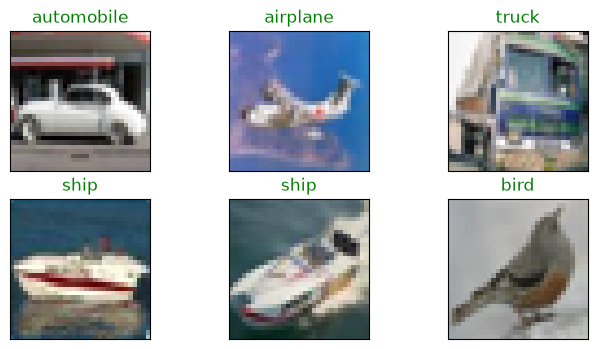

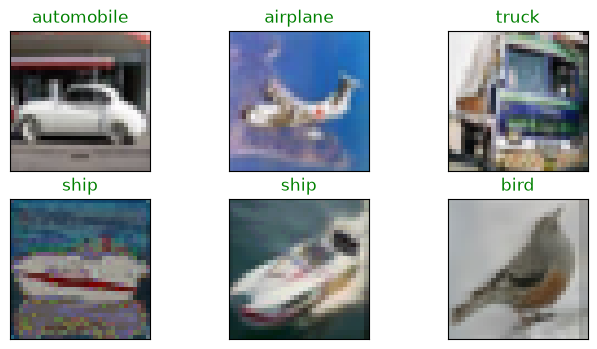

In [58]:
from PIL import Image

def im_plot(x_numpy, y_batch, transform):
    plt.figure(figsize=(8, 4))
    for idx in range(6):
        im=Image.fromarray(x_numpy[idx])
        im=transform(im)

        plt.subplot(2, 3, idx+1, xticks=[], yticks=[])
        plt.imshow(im.permute(1, 2, 0))
        true_class=test_DS.classes[y_batch[idx]]
        plt.title(true_class, color='g')

    print(f'image size={im.shape}')

idx=torch.randint(0, 10000, (6, ))
x_batch=test_DS.data[idx]
target=torch.tensor(test_DS.targets)

y_batch=target[idx]
im_plot(x_batch, y_batch, transform_test)
im_plot(x_batch, y_batch, transform_train)